In [1]:
from langchain_ollama import ChatOllama
from langchain_google_genai import ChatGoogleGenerativeAI
import os
from dotenv import load_dotenv
load_dotenv()
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0
)
llm_ollama = ChatOllama(model = 'llama3.2:3b', temperature=0)

if os.environ.get("GOOGLE_API_KEY"):
    print("Bro API KEY Variable exists")
else:
    raise ValueError("GOOGLE_API_KEY not found")


Bro API KEY Variable exists


## Tools

In [2]:
# TOOL 1 - [News Search Tool]
from langchain_community.tools import DuckDuckGoSearchResults
search_tool = DuckDuckGoSearchResults(description='đây là tool search tin tức trên web')

# TOOL 1 - [Wikipedia Search Tool]
import wikipedia

wikipedia.set_user_agent(
    "langchain-study/0.1 YOUR_EMAIL"
)
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(), description='đây là tool dùng search wikipedia')

C:\Users\MSI\AppData\Local\Temp\ipykernel_11976\936241638.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchResults


In [12]:
from langchain.tools import tool

@tool
def enterprise_tool(query:str) -> str:
    """Đây là tool gửi email cho nhân viên"""

    return 'Email sent'

In [13]:
ToolKit = [search_tool, wikipedia_tool, enterprise_tool]
ToolKit

[DuckDuckGoSearchResults(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'd:\\langchain-study\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='Đây là tool gửi email cho nhân viên', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x000001DB07F4BA60>)]

## ReAct Agent

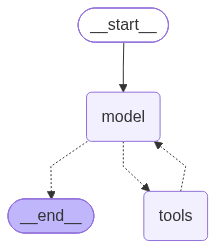

In [17]:
from langchain.agents import create_agent
from langchain_ollama import ChatOllama

model = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0
)
agent = create_agent(model, ToolKit)
agent

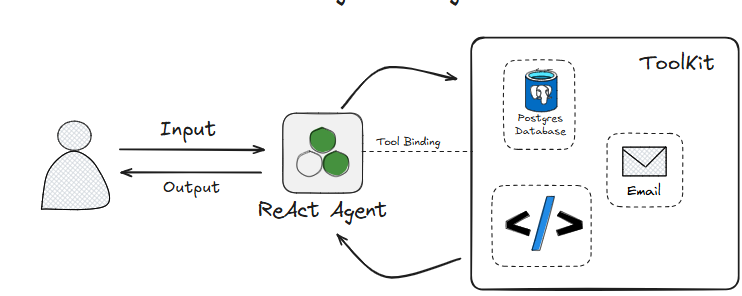

## ReAct Agent Invoke With Streams

In [18]:
example_query = "cho tôi thông tin về các techstack nổi bật của role data engineer hiện tại "

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

cho tôi thông tin về các techstack nổi bật của role data engineer hiện tại 
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Trong những năm gần đây, vai trò **Data Engineer (DE)** đã dịch chuyển mạnh mẽ từ mô hình ETL truyền thống (Hadoop on-premise) sang mô hình **ELT trên Cloud**, **Data Lakehouse**, và **Modern Data Stack (MDS)**.\n\nDưới đây là tổng hợp các công cụ và tech stack nổi bật nhất mà một Data Engineer cần biết hiện nay, được phân theo từng tầng kiến trúc dữ liệu:\n\n---\n\n### 1. Ngôn ngữ lập trình cốt lõi (Core Languages)\n*   **SQL:** Công cụ quan trọng số một, không thể thiếu ở bất kỳ vị trí DE nào.\n*   **Python:** Ngôn ngữ phổ biến nhất để viết pipeline, xử lý dữ liệu (PySpark, Pandas, Polars) và viết DAG (Airflow).\n*   **Scala / Java:** Thường dùng trong các hệ sinh thái Big Data quy mô lớn, tối ưu hóa sâu với Apache Spark 

## Manually Binding The LLM With Tools

In [22]:
# Without Binding
llm_ollama.invoke("cho tôi thông tin về các techstack nổi bật của role data engineer hiện tại ")

AIMessage(content='Các techstack nổi bật của role Data Engineer hiện tại thường bao gồm:\n\n1. **Hadoop và Big Data**: Hadoop, Spark, HBase, Cassandra, và NoSQL databases như MongoDB, Cassandra, và Redis.\n2. **Cloud Computing**: Amazon Web Services (AWS), Microsoft Azure, Google Cloud Platform (GCP), và IBM Cloud.\n3. **Containerization và Orchestration**: Docker, Kubernetes, và containerization tools như rkt và cri-o.\n4. **Programming Languages**: Java, Python, Scala, và C++.\n5. **Data Storage**: Relational databases như MySQL, PostgreSQL, và MongoDB, cũng như các công cụ lưu trữ dữ liệu như HDFS, S3, và GCS.\n6. **Data Processing**: Apache Beam, Apache Flink, Apache Spark, và các công cụ xử lý dữ liệu như Apache Kafka, Apache Storm.\n7. **Machine Learning**: TensorFlow, PyTorch, Scikit-learn, và các thư viện ML như LightGBM, CatBoost.\n8. **Data Visualization**: Tableau, Power BI, D3.js, và các công cụ phân tích dữ liệu như Apache Zeppelin.\n9. **DevOps**: Jenkins, GitLab CI/CD, D

In [23]:
# With Binding
llm_binded = llm_ollama.bind_tools(ToolKit)
llm_binded.invoke("cho tôi thông tin về các techstack nổi bật của role data engineer hiện tại")

AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:3b', 'created_at': '2026-10-27T15:45:27.5948229Z', 'done': True, 'done_reason': 'stop', 'total_duration': 604826300, 'load_duration': 2098800, 'prompt_eval_count': 319, 'prompt_eval_duration': 205886000, 'eval_count': 20, 'eval_duration': 371135000, 'logprobs': None, 'model_name': 'llama3.2:3b', 'model_provider': 'ollama'}, id='lc_run--01a17e09-b1cc-7337-9fde-d1074196234d-0', tool_calls=[{'name': 'wikipedia', 'args': {'query': 'techstack data engineer'}, 'id': '5c1e247e-6a15-4350-8495-ee11c524340f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 319, 'output_tokens': 20, 'total_tokens': 339})